what is knn and all:

So we make a graph and plot the datapoints then we get a sample point of our test sample we measure all the other point's distances from it then we try to find out which class has more points inside K
this K is a number choosen by us 

eg: k=3 {dog, cat, dog} -- majority dog win so dog class
eg2: k=5 {cat,cat,cat,dog,cat} --majority cat win so cat class

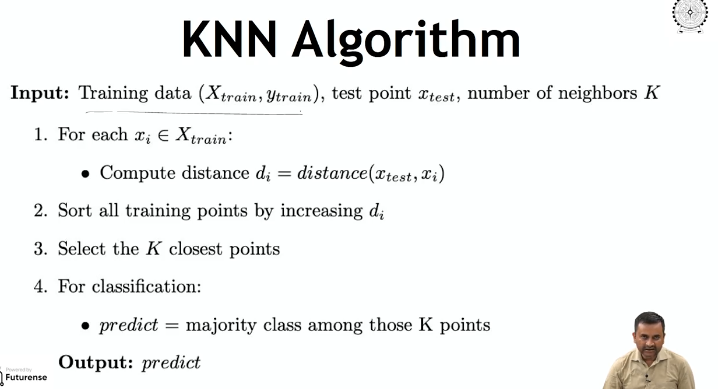

Today we gonna implement it by using Sklearn-kit

Our training dataset will be "MINST"

THIS DATASET CONTENT MANY IMAGES OF HANDWRITTEN DIGITS 

We gonna classify if your sample image is which digit


MNIST (28x28 grayscale digits, 0-9)

In [1]:
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.datasets import fetch_openml #loading dataset
from sklearn.model_selection import train_test_split #splitting train/test data
from sklearn.neighbors import KNeighborsClassifier   #Knn classifier model
from sklearn.metrics import accuracy_score,confusion_matrix #for visualizing performance

# Load MNIST dataset from OpenML

- X contains flatten 28x28 images
- y contains digit labels

same as we learned about KNN

Shape of X: (70000, 784)
Shape of y: (70000,)


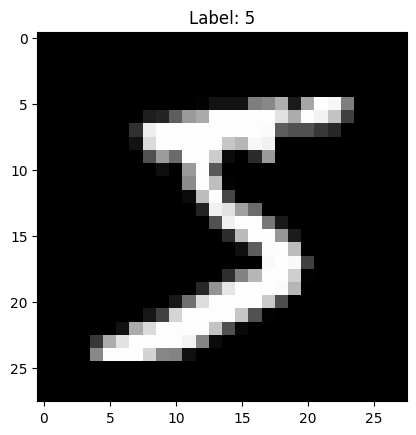

In [ ]:
mnist = fetch_openml('mnist_784', version=1) # 28x28 = 784 is the matrix size
X,y = mnist.data, mnist.target.astype(int)

print('Shape of X:', X.shape)
print('Shape of y:', y.shape)

#Visualize first digits:
plt.imshow(X.iloc[0].values.reshape(28,28), cmap='gray')
plt.title(f'Label: {y[0]}')
plt.show()

This is the main matrix 'X' who have all 70k sample's data see how it looks like bcz its a 28x28 pixel image means 784 pixels total it have columns of all of them storying all those data in matrix form seee

Its "flatten" into a single 784-dim vector

In [4]:
X

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


This is the feature vector it have all the labels with it

In [ ]:
y

0        5
1        0
2        4
3        1
4        9
        ..
69995    2
69996    3
69997    4
69998    5
69999    6
Name: class, Length: 70000, dtype: int64

# Train-Test Split

- Split data into training (80%) and testing (20%)
- **random_state=42** ensures reproducibility

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42) #test_size means how much percent gose on testing like current i am ginving it 0.2 or 20%
#random_state is usded for suffeling applied to the data before applying the split if I make it 42 my friend do it 42 then we get same results bcz we are suffeling same way

print("Training Samples: ", X_train.shape)
print("Training Samples: ", X_test.shape) # 70k x 20/100 = 14k going for testing :D

Training Samples:  (56000, 784)
Training Samples:  (14000, 784)


# Train KNN

- Use k=3 neighbors
- KNN is a "lazy learner" : it stores training data, no actual training :D

In [ ]:
knn= KNeighborsClassifier(n_neighbors=3) #we set the k values here
knn.fit(X_train, y_train) #we are making a knn model and giving it all the training data to remember their positions

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


# Predict & Evaluate

- Predict on test set
- Calculate accurace and condusion matrix

In [ ]:
y_pred = knn.predict(X_test) #here its testing the X_test samples on the data we fit before, like its finding the distances from each others which is near in top 3 which class is most
acc = accuracy_score(y_test, y_pred) #we are giving y_test which is the labels of the samples and y pred which is the predicted labels
print("Test accuracy: ", acc)

cm = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n", cm) 

Test accuracy:  0.9712857142857143
Confusion Matrix: 
 [[1335    0    5    0    0    0    1    1    1    0]
 [   0 1591    3    0    1    1    0    3    0    1]
 [   8   14 1333    1    1    1    4   13    3    2]
 [   0    3   12 1382    0   10    2   10    7    7]
 [   3    9    1    0 1248    0    2    4    1   27]
 [   4    5    0   13    4 1234   12    0    1    0]
 [   5    1    0    0    4    3 1383    0    0    0]
 [   1   17    4    0    2    0    0 1467    1   11]
 [   6   13    8   21    4   16    3    6 1269   11]
 [   6    6    3   14   20    0    0   14    1 1356]]


# Visualize Predictions

- Show first 10 test images with predicted labels

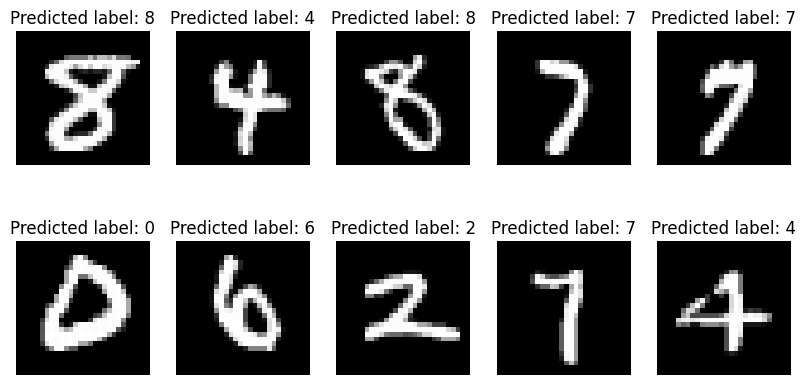

In [21]:
plt.figure(figsize=(10,5))
for i in range(10):
    plt.subplot(2,5,i+1) #we are setting the subplot total number of rows and cols and current subplot's position
    plt.imshow(X_test.iloc[i].values.reshape(28,28), cmap='gray') #here we are loading the 784 vector as 28x28 and mapping them so we can visualize them
    plt.title(f'Predicted label: {y_pred[i]}') #y_pred variable who label data of all predicted vales
    plt.axis('off') #try to enable or disable it to understand how the 28x28 samples becoming the image
plt.show()

# Explore Neighbors

- Show K=3 nearest neighbors for first test image
- Compare predicted label vs true label


c:\Users\surya\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


Predicted label: 5
True label:  5


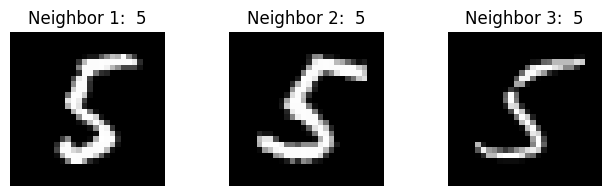

In [40]:
distance, indices = knn.kneighbors([X_test.iloc[45]])
print("Predicted label:", y_pred[45])
print('True label: ', y_test.iloc[45]) #as we know y_test holds all the names of samples

plt.figure(figsize=(8,2))
for index , indi in enumerate(indices[0]):
    plt.subplot(1,3,index+1)
    plt.imshow(X_train.iloc[indi].values.reshape(28,28), cmap='gray')
    plt.title(f'Neighbor {index+1}:  {y_train.iloc[indi]}')
    plt.axis('off')
plt.show()

In [ ]:
#this is the id number of the neighbor like we had 56k training data right so among them these are the closest of the test sample number: 45
indices[0]

array([53344, 37605, 43634])

In [41]:
#this is their total distance among them
distance

array([[1272.8503447 , 1290.8117601 , 1350.79347052]])